In [1]:
%pip install opencv-python numpy matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Dimensões: (1600, 1200, 3)


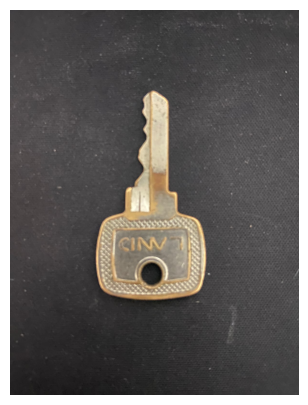

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imagem = cv2.imread("../imagens/PD 442.jpeg")

if imagem is None:
    raise FileNotFoundError("Imagem não encontrada")

imagem_rgb = cv2.cvtColor(
    imagem,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 5))
plt.imshow(imagem_rgb)
plt.axis("off")

print("Dimensões:", imagem.shape)

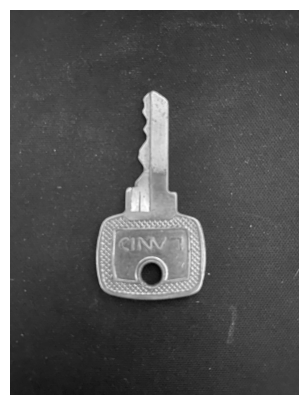

In [12]:
gray = cv2.cvtColor(
    imagem,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(10, 5))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

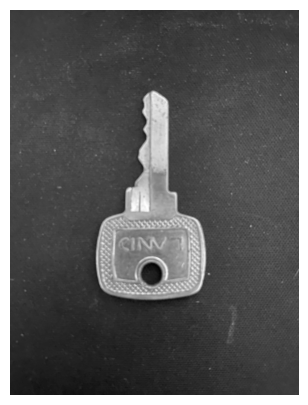

In [53]:
blur = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

plt.figure(figsize=(10, 5))
plt.imshow(blur, cmap="gray")
plt.axis("off")
plt.show()

Limiar escolhido: 118.0


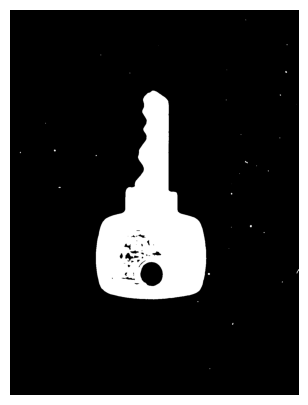

In [54]:
limiar, binary = cv2.threshold(
    blur,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

binary_inverted = cv2.bitwise_not(binary)

print("Limiar escolhido:", limiar)

plt.figure(figsize=(10, 5))
plt.imshow(binary_inverted, cmap="gray")
plt.axis("off")
plt.show()

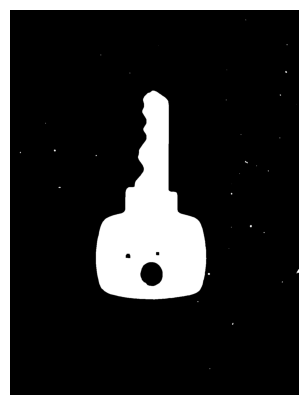

In [55]:
kernel = np.ones((11, 11), dtype=np.uint8)

closed = cv2.morphologyEx(
    binary_inverted,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(closed, cmap="gray")
plt.axis("off")
plt.show()

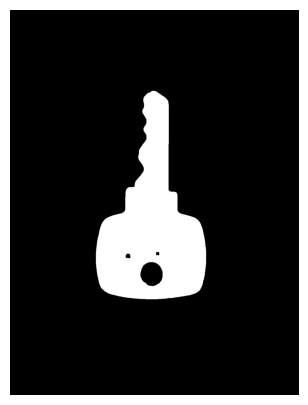

In [56]:
kernel = np.ones((11, 11), dtype=np.uint8)

opened = cv2.morphologyEx(
    closed,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(opened, cmap="gray")
plt.axis("off")
plt.show()

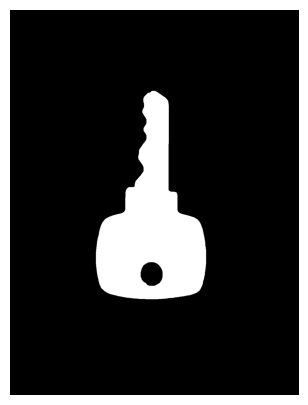

In [57]:
kernel = np.ones((15, 15), dtype=np.uint8)

cleaned = cv2.morphologyEx(
    opened,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 5))
plt.imshow(cleaned, cmap="gray")
plt.axis("off")
plt.show()

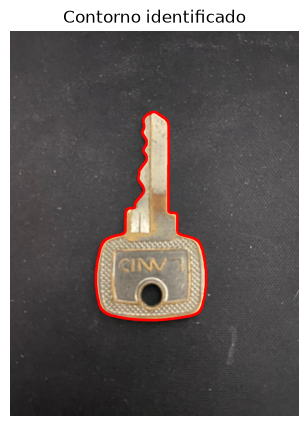

In [51]:
contours, hierarchy = cv2.findContours(
    cleaned,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)

if not contours:
    raise ValueError("Nenhum contorno encontrado")

contorno_chave = max(
    contours,
    key=cv2.contourArea
)

resultado = imagem.copy()

cv2.drawContours(
    resultado,
    [contorno_chave],
    -1,
    (0, 0, 255),
    10
)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))
plt.title("Contorno identificado")
plt.axis("off")
plt.show()

In [48]:
area = cv2.contourArea(contorno_chave)

perimetro = cv2.arcLength(
    contorno_chave,
    True
)

x, y, w, h = cv2.boundingRect(contorno_chave)

momentos = cv2.moments(contorno_chave)

if momentos["m00"] != 0:
    cx = int(momentos["m10"] / momentos["m00"])
    cy = int(momentos["m01"] / momentos["m00"])
else:
    cx, cy = x + w // 2, y + h // 2

print("Área:", area, "pixels²")
print("Perímetro:", perimetro, "pixels")
print("Largura da bounding box:", w)
print("Altura da bounding box:", h)
print("Centroide:", (cx, cy))

Área: 213163.0 pixels²
Perímetro: 2450.2194669246674 pixels
Largura da bounding box: 458
Altura da bounding box: 866
Centroide: (589, 903)
